# 02｜数据与可视化：先看清数据，再谈模型

**前置：**第 00、01 课。**预计时间：**60—75 分钟。**产物：**一份合成数据观察记录、三个互不重叠的数据集和一个可评估的简单基线。

本课沿用房屋主题。所有样本由代码生成，面积用平方米，房龄用年，价格用“模拟万元”；样本编号也为合成。我们在教学规则中人为加入面积、房龄和随机扰动，练习数据处理与评估。现实估价还需要地段、时点和可靠的数据来源。

完成后你将能够：区分特征与目标；读表、看图并发现缺失值；先划分数据再计算填补规则；解释常数预测的误差。

## 1. 准备工具，处理中文显示

数值计算库 NumPy（Numerical Python）负责造数据，表格数据处理库 pandas 管理数据表，绘图库 Matplotlib 负责观察规律。数据表（DataFrame）可以理解为带有行索引和列名的二维表。

下面的代码从可用字体中选择支持中文的字体。若看到字体提示，先安装相应字体并重启内核。字体选择只影响文字显示。

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
font_candidates = [
    "Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Source Han Sans SC",
    "WenQuanYi Micro Hei", "PingFang SC", "Heiti SC", "Arial Unicode MS",
]
chinese_font = next((name for name in font_candidates if name in available_fonts), None)
if chinese_font:
    plt.rcParams["font.sans-serif"] = [chinese_font]
else:
    print("建议安装思源黑体或 Noto Sans CJK SC，并重启内核，以显示中文图表。")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
print("工具版本：", np.__version__, pd.__version__)

工具版本： 2.5.5 3.1.1


## 2. 生成一张带缺失值的数据表

随机种子固定为 42：在同一套库环境中，从头运行会得到相同数据。先生成完整样本，再人为抹去部分面积和房龄，模拟采集遗漏。目标价格保持完整。

生成规则是 `价格 = 1.8 × 面积 - 0.9 × 房龄 + 25 + 随机扰动`。你已经知道生成规律，仍要按正确流程练习；现实任务中通常要从样本探索规律。

In [ ]:
rng = np.random.default_rng(42)
n_samples = 150
area = rng.uniform(40, 140, n_samples)
age = rng.integers(0, 31, n_samples).astype(float)
price = 1.8 * area - 0.9 * age + 25 + rng.normal(0, 12, n_samples)

data = pd.DataFrame({
    "样本编号": np.arange(n_samples),
    "面积": area,
    "房龄": age,
    "模拟价格": price,
})
data.loc[rng.choice(n_samples, 12, replace=False), "面积"] = np.nan
data.loc[rng.choice(n_samples, 8, replace=False), "房龄"] = np.nan
print("数据形状：", data.shape)
data.head()

数据形状： (150, 4)


,样本编号,面积,房龄,模拟价格
0,0,NaN,11.0,218.060777
1,1,83.887844,NaN,150.811813
2,2,125.859792,0.0,254.457587
3,3,109.736803,27.0,200.345126
4,4,49.417735,16.0,86.539266


先不急着填补。每行是一套合成房屋，每列记录一个属性。样本编号只用于跟踪样本，特征（feature）是预测时可用的信息，目标（target）是希望预测的值。

本课特征是面积和房龄；模拟价格是目标。将目标直接放进特征，会提前把答案交给预测流程，产生数据泄漏（data leakage）。

In [ ]:
feature_cols = ["面积", "房龄"]
target_col = "模拟价格"
X = data[feature_cols]
y = data[target_col]

print("特征矩阵：", X.shape, "目标向量：", y.shape)
print("各列缺失数量：")
print(data.isna().sum())
assert target_col not in X.columns
assert "样本编号" not in X.columns
assert y.notna().all()

特征矩阵： (150, 2) 目标向量： (150,)
各列缺失数量：
样本编号     0
面积      12
房龄       8
模拟价格     0
dtype: int64


## 3. 先划分训练、验证、测试数据

训练集用于学习参数和处理规则；验证集用于比较候选方案；测试集留到最终评估。这里按 60%、20%、20%随机划分，相应样本数为 90、30、30。随机打乱适合本课独立生成的样本；时间序列应考虑按时间划分，同一实体的重复记录应考虑按组划分。

先划分再处理缺失值，保证验证和测试样本的统计信息没有提前参与规则计算。

In [ ]:
split_rng = np.random.default_rng(42)
indices = split_rng.permutation(len(data))
n_train = int(len(data) * 0.6)
n_valid = int(len(data) * 0.2)
train = data.iloc[indices[:n_train]].copy()
valid = data.iloc[indices[n_train:n_train + n_valid]].copy()
test = data.iloc[indices[n_train + n_valid:]].copy()

train_ids = set(train["样本编号"])
valid_ids = set(valid["样本编号"])
test_ids = set(test["样本编号"])
assert train_ids.isdisjoint(valid_ids)
assert train_ids.isdisjoint(test_ids)
assert valid_ids.isdisjoint(test_ids)
assert len(train) + len(valid) + len(test) == len(data)
print("训练、验证、测试样本数：", len(train), len(valid), len(test))

训练、验证、测试样本数： 90 30 30


## 4. 看训练数据：统计表和散点图

均值展示平均水平，中位数位于排序后的中间位置。`describe()` 还会显示标准差与分位数，`count` 记录非缺失值数量。先描述训练集；测试集继续留出。

In [ ]:
train[feature_cols + [target_col]].describe().round(2)

,面积,房龄,模拟价格
count,83.00,86.00,90.00
mean,86.41,14.92,168.52
std,27.38,9.84,50.56
min,40.74,0.00,52.39
25%,60.85,7.00,132.74
50%,86.19,13.00,167.64
75%,110.00,23.75,203.63
max,137.56,30.00,270.10


每个点对应一个训练样本，横轴为面积，纵轴为模拟价格，颜色表示房龄。面积缺失的样本暂时跳过；此处观察原始训练数据，避免把填补值误当成采集结果。

先预测：面积与模拟价格会呈现什么关系？较大的面积能否完全决定价格？

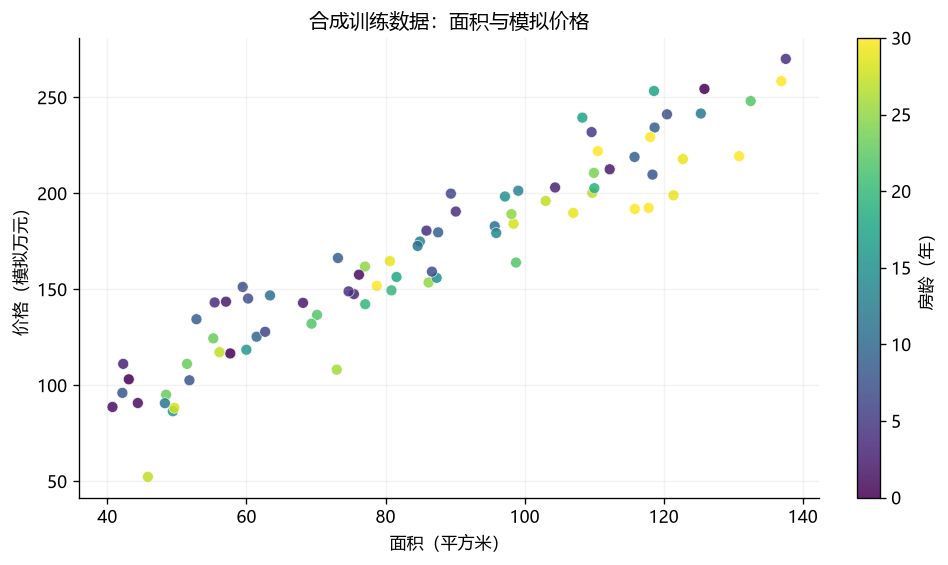

In [ ]:
plot_data = train.dropna(subset=["面积", "房龄", target_col])
fig, ax = plt.subplots(figsize=(7.8, 4.6), layout="constrained")
points = ax.scatter(
    plot_data["面积"], plot_data[target_col], c=plot_data["房龄"],
    cmap="viridis", s=43, alpha=0.85, edgecolors="white", linewidth=0.4,
)
fig.colorbar(points, ax=ax, label="房龄（年）")
ax.set(title="合成训练数据：面积与模拟价格", xlabel="面积（平方米）", ylabel="价格（模拟万元）")
ax.grid(alpha=0.16)
plt.show()

面积增加时价格整体上升，与人为生成规则一致；同一面积附近仍有波动，因为房龄和随机扰动也参与了价格计算。图中观察到的关系适用于这组数据；迁移到真实任务时，需要重新收集数据并评估。

**主动实验：**在一份新单元格中复制上面的画图代码，将横轴改为房龄，颜色改为面积，并同步修改标题、坐标与色条。先写下一句预测，再看图核对。源数据与训练划分保持一致。

## 5. 只用训练集的规则填补缺失值

本课用训练特征的中位数填补缺失值，再把相同规则应用到三个数据集。验证集和测试集参与的是规则的应用步骤。目标值无需填补。

中位数填补会把缺失样本放到同一位置，可能掩盖某些数据特点。后续可比较其他方案；本课先掌握规则从哪来、用到哪去。

In [ ]:
train_medians = train[feature_cols].median()
X_train = train[feature_cols].fillna(train_medians)
X_valid = valid[feature_cols].fillna(train_medians)
X_test = test[feature_cols].fillna(train_medians)
y_train = train[target_col]
y_valid = valid[target_col]

assert np.isfinite(train_medians.to_numpy()).all()
assert not X_train.isna().any().any()
assert not X_valid.isna().any().any()
assert not X_test.isna().any().any()
print("训练集计算得到的填补值：")
print(train_medians.round(2))

训练集计算得到的填补值：
面积    86.19
房龄    13.00
dtype: float64


## 6. 建立一个简单基线

基线（baseline）提供比较起点。我们先对所有验证样本都预测“训练集平均价格”，暂时完全忽略面积和房龄。后续模型应在同一划分和同一评估方法下，与这个起点比较。

平均绝对误差（MAE，Mean Absolute Error）计算每个预测误差的绝对值再取平均：

$$\operatorname{MAE}=\frac{1}{m}\sum_{i=1}^{m}|y_i-\hat y_i|$$

其中 $m$ 是评估样本数，$y_i$ 是样本目标，$\hat y_i$ 是预测。训练均值是直观的常数基线；如果要寻找训练集上平均绝对误差最小的常数，应使用训练目标的中位数。

In [ ]:
baseline_price = float(y_train.mean())
valid_predictions = np.full(len(valid), baseline_price)
valid_mae = float(np.mean(np.abs(y_valid.to_numpy() - valid_predictions)))

print(f"常数预测价格：{baseline_price:.2f} 模拟万元")
print(f"验证集平均绝对误差：{valid_mae:.2f} 模拟万元")
assert valid_predictions.shape == y_valid.shape

常数预测价格：168.52 模拟万元
验证集平均绝对误差：36.51 模拟万元


把验证样本按其在验证集中的顺序画出：实心点是合成目标值，虚线是常数预测。横轴序号用于看清差距，未编码房屋面积等含义。

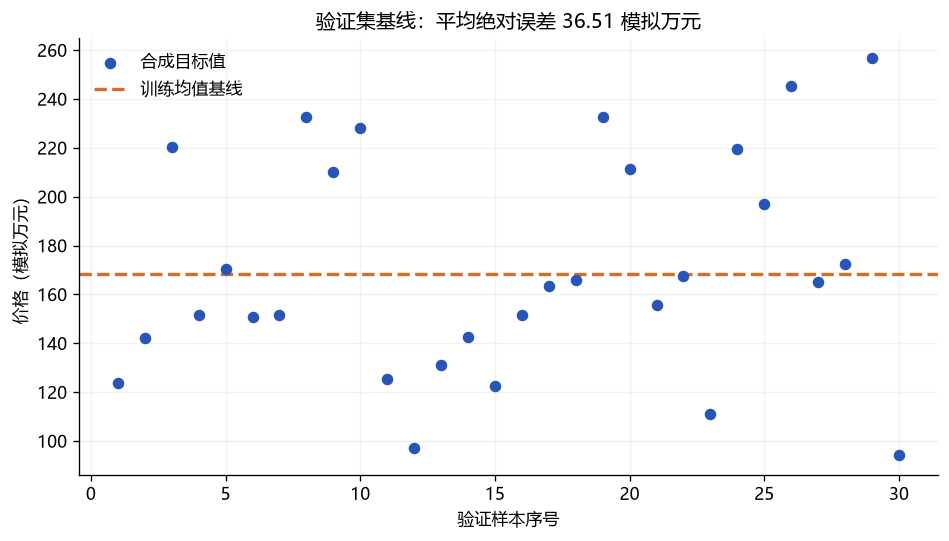

In [ ]:
fig, ax = plt.subplots(figsize=(7.8, 4.4), layout="constrained")
positions = np.arange(1, len(valid) + 1)
ax.scatter(positions, y_valid.to_numpy(), color="#2855b8", s=35, label="合成目标值", zorder=3)
ax.axhline(baseline_price, color="#d76b2a", linestyle="--", linewidth=2, label="训练均值基线")
ax.set(
    title=f"验证集基线：平均绝对误差 {valid_mae:.2f} 模拟万元",
    xlabel="验证样本序号", ylabel="价格（模拟万元）",
)
ax.legend(frameon=False)
ax.grid(alpha=0.16)
plt.show()

常数预测没有利用特征，因此各样本的预测值相同。较大、较小的目标值都可能与它相差很远。本课给出一个可以复现的比较起点，下一阶段再训练利用面积的模型。

现在继续保留测试集。若我们看过测试误差，再据此改模型或处理方法，测试集便参与了方案选择。完成方案选择后，再进行最终评估。

## 7. 练习一：隔离特征和目标

从验证集 `valid` 选出面积与房龄两列，保持这个列顺序，放到 `exercise_features`。先完成赋值，再将自检开关改成 `True`。这里检查列选择，不要求填补后的版本。

In [ ]:
exercise_features = None
check_exercise_features = False
if check_exercise_features:
    assert isinstance(exercise_features, pd.DataFrame), "请先选择特征列"
    assert exercise_features.columns.tolist() == ["面积", "房龄"]
    assert exercise_features.equals(valid[feature_cols])
    print("练习一通过：目标和样本编号均已隔离")

<details>
<summary>练习一：提示与参考解</summary>

提示：使用列名列表选择多列，会保留二维数据表。

```python
exercise_features = valid[["面积", "房龄"]]
assert exercise_features.columns.tolist() == feature_cols
assert target_col not in exercise_features.columns
assert exercise_features.equals(valid[feature_cols])
```
</details>

## 8. 练习二：手工核对平均绝对误差

三个合成样本的目标是 `[100, 130, 160]`，预测统一为 `120`。先逐个计算绝对误差，再将平均值写入 `exercise_mae`。填写后开启自检。

In [ ]:
exercise_mae = None
check_exercise_mae = False
if check_exercise_mae:
    assert isinstance(exercise_mae, (int, float)), "请先填写数值结果"
    assert np.isclose(exercise_mae, 70 / 3)
    print("练习二通过：平均误差约为 23.33")

<details>
<summary>练习二：提示与参考解</summary>

三个绝对误差为 20、10、40。先求和，再除以样本数。

```python
exercise_mae = (20 + 10 + 40) / 3
assert np.isclose(exercise_mae, 70 / 3)
```
</details>

## 解释、复现与下课入口

用自己的话回答：如果把所有样本的中位数用于填补，再划分数据，哪些信息提前参与了处理？为什么此处先比较验证误差？下一课的模型至少应与什么结果比较？

- [ ] 能解释一行样本、特征、目标和样本编号的区别。
- [ ] 能读懂统计表，描述图中整体趋势与离散程度。
- [ ] 能划分互不重叠的数据，并用训练统计处理留出数据。
- [ ] 能计算常数基线的验证误差，说明测试集的最终用途。
- [ ] 能重启内核后从头运行，重新得到同样的数据和结果。

上一课：[01｜数组与向量运算](01_数组与向量运算.ipynb)。下一阶段：`课程/01_回归与分类/03_单变量线性回归.ipynb`（计划中的课程，待上线）。

拓展阅读：[pandas 官方入门](https://pandas.pydata.org/docs/getting_started/intro_tutorials/)、[Matplotlib 官方快速入门](https://matplotlib.org/stable/users/explain/quick_start.html)。